Total jobs scraped: 30

Missing values:
Title             0
Company           0
Location          0
Type              0
Posted            0
Remote            0
Clean_Location    0
dtype: int64

Duplicate rows: 0

Job Type Distribution:
Type
intern       9
full-time    9
part-time    6
contract     6
Name: count, dtype: int64

Location Distribution:
Clean_Location
Austin, TX, US    9
Singapore, SG     4
Amsterdam, NL     4
Lisbon, PT        3
Remote            3
London, UK        3
Bengaluru, IN     3
Mumbai, IN        1
Name: count, dtype: int64

Remote jobs: 12
Non-remote jobs: 18

Remote Jobs by Type:
Type
contract     3
full-time    3
intern       2
part-time    4
Name: Remote, dtype: int64

Latest Job:
Title             Senior PHP Engineer
Company                   Carbon Yard
Location                Remote Remote
Type                        part-time
Posted            2026-10-01 00:00:00
Remote                           True
Clean_Location                 Remote
Name: 4, dtype: ob

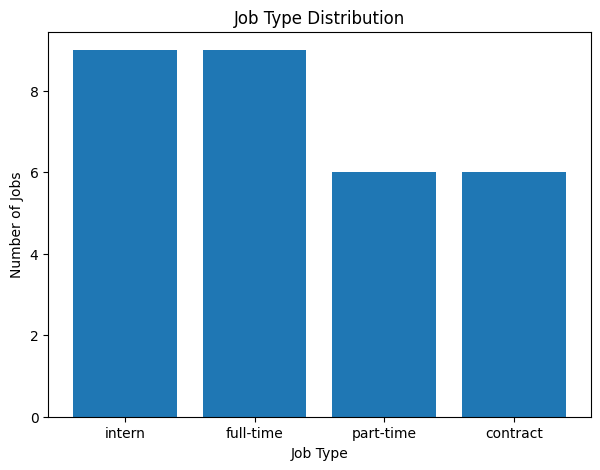

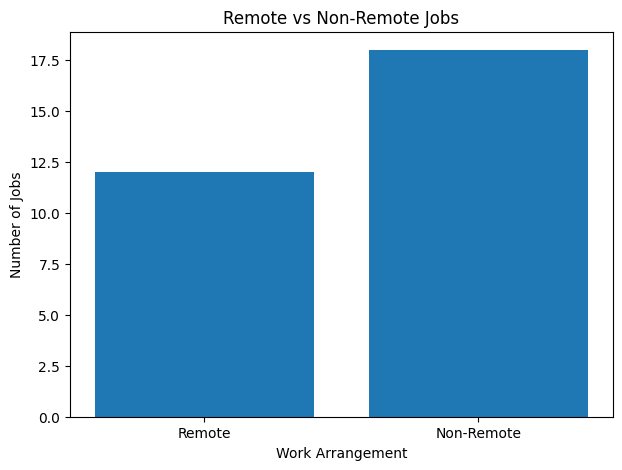

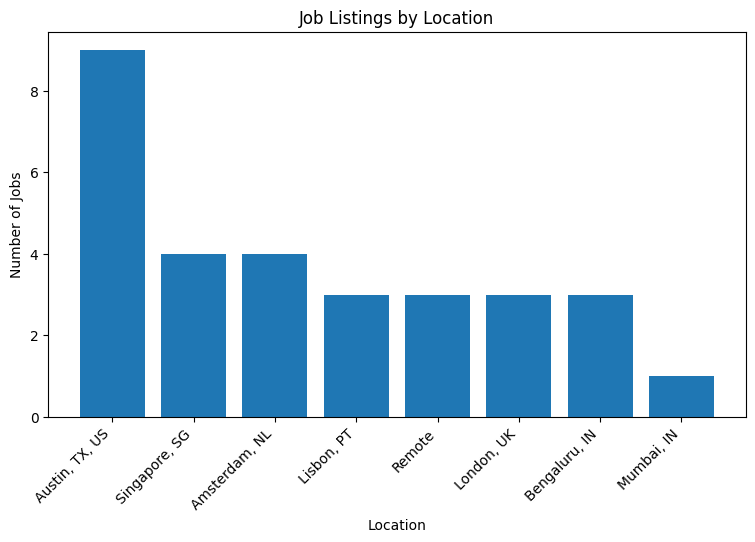

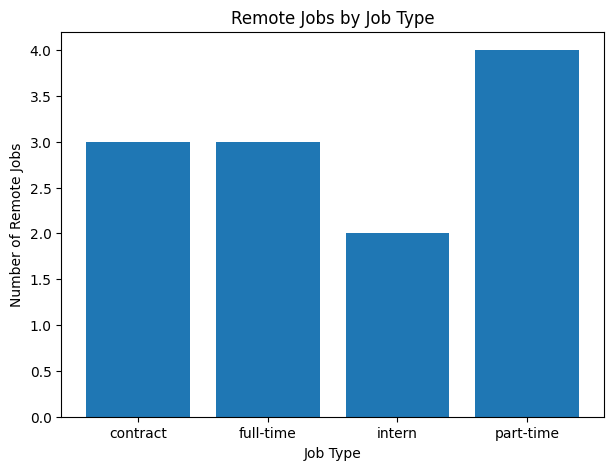


Final dataset saved successfully!

Final dataset shape: (30, 7)


In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt


all_data = []

for page in range(1, 7):

    url = f"https://practice.scrapingcentral.com/jobs?page={page}"
    response = requests.get(url)

    soup = BeautifulSoup(response.text, "html.parser")
    jobs = soup.find_all("tr")[1:]

    for job in jobs:
        cells = job.find_all("td")

        title = cells[0].text.strip()
        company = cells[1].text.strip()
        location = cells[2].text.strip()
        job_type = cells[3].text.strip()
        posted = cells[4].text.strip()

        all_data.append([
            title,
            company,
            location,
            job_type,
            posted
        ])


print("Total jobs scraped:", len(all_data))


df = pd.DataFrame(
    all_data,
    columns=["Title", "Company", "Location", "Type", "Posted"]
)


df["Posted"] = pd.to_datetime(df["Posted"])

df["Remote"] = df["Location"].str.contains(
    "Remote",
    case=False
)

df["Clean_Location"] = df["Location"].str.replace(
    " Remote",
    "",
    regex=False
)


print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())



type_counts = df["Type"].value_counts()

print("\nJob Type Distribution:")
print(type_counts)


location_counts = df["Clean_Location"].value_counts()

print("\nLocation Distribution:")
print(location_counts)


remote_jobs = df["Remote"]

print("\nRemote jobs:", remote_jobs.sum())
print("Non-remote jobs:", (~remote_jobs).sum())

remote_by_type = df.groupby("Type")["Remote"].sum()

print("\nRemote Jobs by Type:")
print(remote_by_type)


latest_job = df.loc[df["Posted"].idxmax()]

print("\nLatest Job:")
print(latest_job)


latest_jobs = df.sort_values(
    "Posted",
    ascending=False
).head(10)

print("\nLatest 10 Jobs:")
print(latest_jobs[["Title", "Company", "Type", "Posted"]])


plt.figure(figsize=(7, 5))

plt.bar(type_counts.index, type_counts.values)

plt.title("Job Type Distribution")
plt.xlabel("Job Type")
plt.ylabel("Number of Jobs")

plt.savefig(
    "job_type_distribution1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


remote_counts = [
    remote_jobs.sum(),
    (~remote_jobs).sum()
]

labels = ["Remote", "Non-Remote"]

plt.figure(figsize=(7, 5))

plt.bar(labels, remote_counts)

plt.title("Remote vs Non-Remote Jobs")
plt.xlabel("Work Arrangement")
plt.ylabel("Number of Jobs")

plt.savefig(
    "remote_vs_nonremote.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(figsize=(9, 5))

plt.bar(
    location_counts.index,
    location_counts.values
)

plt.title("Job Listings by Location")
plt.xlabel("Location")
plt.ylabel("Number of Jobs")

plt.xticks(rotation=45, ha="right")

plt.savefig(
    "job_location_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()




plt.figure(figsize=(7, 5))

plt.bar(
    remote_by_type.index,
    remote_by_type.values
)

plt.title("Remote Jobs by Job Type")
plt.xlabel("Job Type")
plt.ylabel("Number of Remote Jobs")

plt.savefig(
    "remote_jobs_by_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


df.to_csv(
    "job_listings_final.csv",
    index=False
)

print("\nFinal dataset saved successfully!")

print("\nFinal dataset shape:", df.shape)